
# Titanic Dataset — Exploratory Data Analysis (EDA)

## Coding Samurai Data Science Internship

**Objective:** Explore the Titanic passenger dataset to understand survival patterns and relationships between passenger characteristics and survival.

### Key Activities
- Inspect and understand the dataset
- Identify and handle missing values
- Analyze passenger age, gender, and class
- Visualize survival patterns
- Create a correlation heatmap
- Summarize findings and conclusions


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Titanic EDA project started successfully!")
print("Libraries imported successfully.")


Titanic EDA project started successfully!
Libraries imported successfully.


In [2]:

# Load the Titanic dataset
titanic = sns.load_dataset("titanic")

print("Dataset loaded successfully!")
print("Dataset shape:", titanic.shape)

# Display the first five rows
display(titanic.head())


Dataset loaded successfully!
Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:

# Display all column names
print("Column names:")
print(titanic.columns.tolist())

# Check dataset structure and data types
print("\nDataset information:")
titanic.info()

# Display basic statistical information
print("\nNumerical summary:")
display(titanic.describe())


Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:

# Count missing values in every column
print("Missing values in each column:")
print(titanic.isnull().sum())

# Calculate missing-value percentages
missing_percentage = (
    titanic.isnull().mean() * 100
).sort_values(ascending=False)

print("\nMissing-value percentage:")
display(missing_percentage[missing_percentage > 0])


Missing values in each column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Missing-value percentage:


,0
deck,77.216611
age,19.865320
embarked,0.224467
embark_town,0.224467


Survival counts:
survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
survived
0    61.62
1    38.38
Name: proportion, dtype: float64


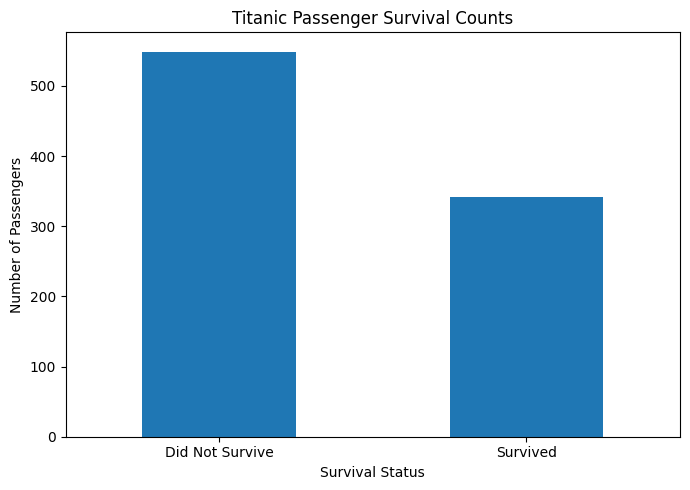

In [5]:

# Count survivors and non-survivors
survival_counts = titanic["survived"].value_counts().sort_index()

print("Survival counts:")
print(survival_counts)

# Calculate survival percentages
survival_percentage = (
    titanic["survived"].value_counts(normalize=True).sort_index() * 100
)

print("\nSurvival percentages:")
print(survival_percentage.round(2))

# Visualize the results
survival_counts.index = ["Did Not Survive", "Survived"]

survival_counts.plot(
    kind="bar",
    figsize=(7, 5),
    title="Titanic Passenger Survival Counts"
)

plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Passenger counts by gender:


,Did Not Survive,Survived
sex,,
female,81,233
male,468,109



Survival rate by gender (%):


,survived
sex,
female,74.20
male,18.89


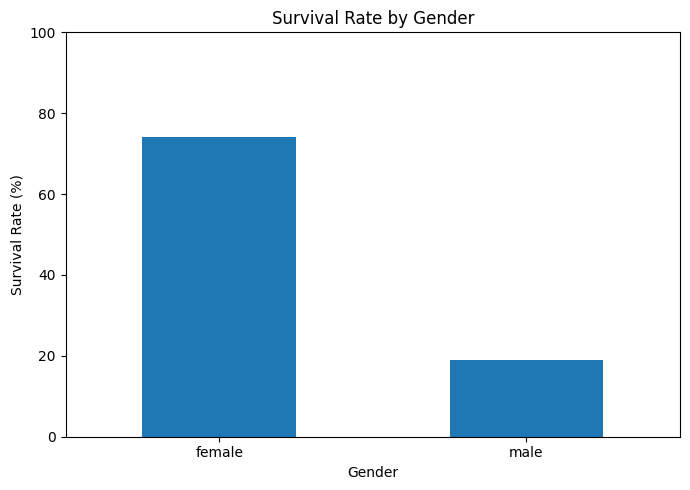

In [6]:

# Count passengers by gender and survival status
gender_counts = pd.crosstab(
    titanic["sex"],
    titanic["survived"]
)

gender_counts.columns = ["Did Not Survive", "Survived"]

print("Passenger counts by gender:")
display(gender_counts)

# Calculate survival rate for each gender
gender_survival_rate = (
    titanic.groupby("sex", observed=True)["survived"]
    .mean() * 100
)

print("\nSurvival rate by gender (%):")
display(gender_survival_rate.round(2))

# Create a chart
gender_survival_rate.plot(
    kind="bar",
    figsize=(7, 5),
    title="Survival Rate by Gender"
)

plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


In [7]:

# Count passengers by class and survival status
class_counts = pd.crosstab(
    titanic["class"],
    titanic["survived"]
)

class_counts.columns = ["Did Not Survive", "Survived"]

print("Passenger counts by class:")
display(class_counts)

# Calculate survival rates by class
class_survival_rate = (
    titanic.groupby("class", observed=True)["survived"]
    .mean() * 100
)

print("\nSurvival rate by passenger class (%):")
display(class_survival_rate.round(2))


Passenger counts by class:


,Did Not Survive,Survived
class,,
First,80,136
Second,97,87
Third,372,119



Survival rate by passenger class (%):


,survived
class,
First,62.96
Second,47.28
Third,24.24


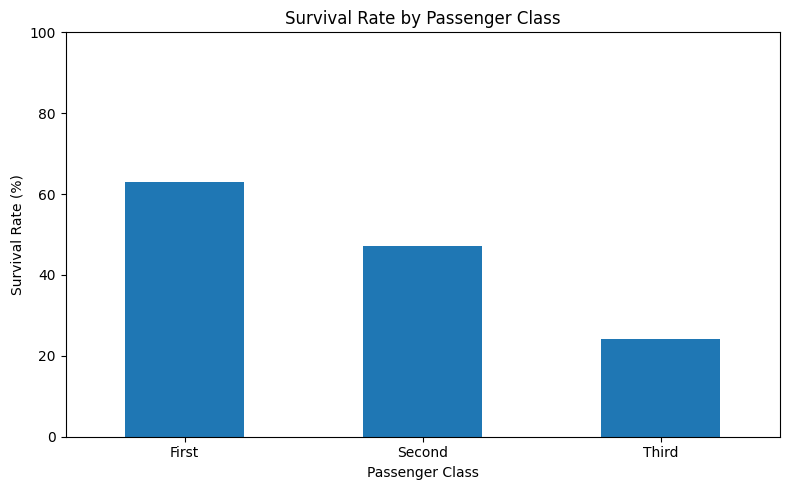

In [8]:

class_survival_rate.plot(
    kind="bar",
    figsize=(8, 5),
    title="Survival Rate by Passenger Class"
)

plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


Passenger age statistics:


,age
count,714.000000
mean,29.699118
std,14.526497
min,0.420000
25%,20.125000
50%,28.000000
75%,38.000000
max,80.000000



Median passenger age: 28.0


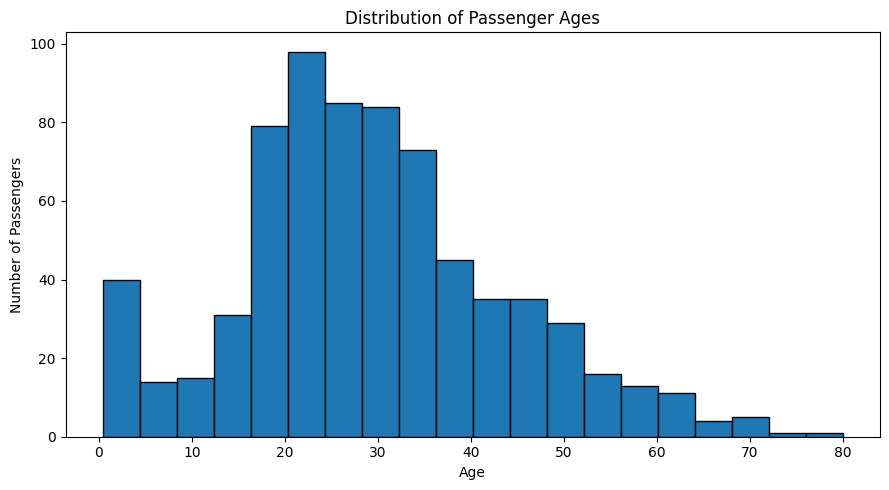

In [9]:

# Summary statistics for passenger ages
print("Passenger age statistics:")
display(titanic["age"].describe())

# Calculate the median age
print("\nMedian passenger age:", titanic["age"].median())

# Plot the age distribution
plt.figure(figsize=(9, 5))

plt.hist(
    titanic["age"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


Age statistics by survival status:


,count,mean,median
Did Not Survive,424,30.63,28.0
Survived,290,28.34,28.0


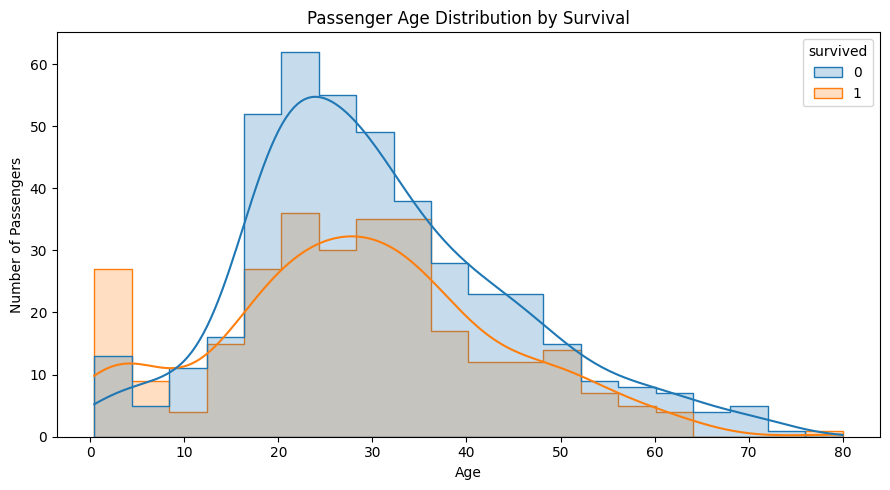

In [10]:

# Compare ages of passengers who survived and did not survive
age_summary = (
    titanic.groupby("survived")["age"]
    .agg(["count", "mean", "median"])
)

age_summary.index = ["Did Not Survive", "Survived"]

print("Age statistics by survival status:")
display(age_summary.round(2))

# Visualize age distributions
plt.figure(figsize=(9, 5))

sns.histplot(
    data=titanic,
    x="age",
    hue="survived",
    bins=20,
    kde=True,
    element="step"
)

plt.title("Passenger Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


In [11]:

# Create a copy of the dataset
titanic_clean = titanic.copy()

# Fill missing ages using the median age
titanic_clean["age"] = titanic_clean["age"].fillna(
    titanic_clean["age"].median()
)

# Fill missing embarkation values with the most common category
most_common_embarked = titanic_clean["embarked"].mode()[0]

titanic_clean["embarked"] = titanic_clean["embarked"].fillna(
    most_common_embarked
)

# Fill the corresponding town values consistently
most_common_town = titanic_clean["embark_town"].mode()[0]

titanic_clean["embark_town"] = titanic_clean["embark_town"].fillna(
    most_common_town
)

# Check remaining missing values
print("Missing values after cleaning:")
print(titanic_clean.isnull().sum())


Missing values after cleaning:
survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      0
alive            0
alone            0
dtype: int64


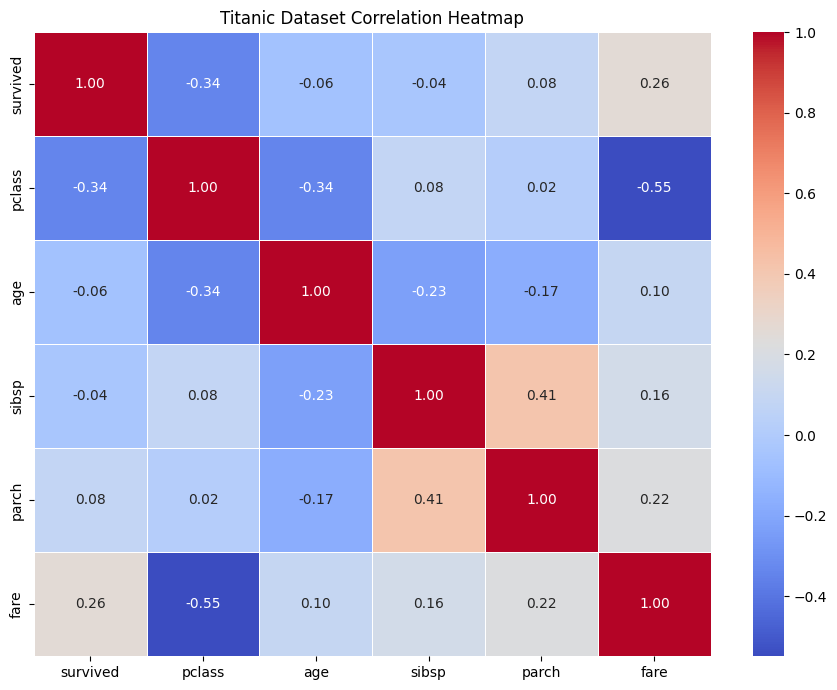

In [12]:

# Select numerical columns relevant to the analysis
numeric_columns = [
    "survived",
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

correlation_matrix = titanic_clean[numeric_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Titanic Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()


In [13]:

# Step 13: Generate key findings from the dataset

total_passengers = len(titanic_clean)
total_survived = int(titanic_clean["survived"].sum())
total_not_survived = total_passengers - total_survived

overall_survival_rate = (
    total_survived / total_passengers
) * 100

gender_rates = (
    titanic_clean.groupby("sex")["survived"].mean() * 100
)

class_rates = (
    titanic_clean.groupby("class", observed=True)["survived"].mean() * 100
)

median_age = titanic_clean["age"].median()
median_fare = titanic_clean["fare"].median()

print("=" * 50)
print("TITANIC DATASET EDA — KEY FINDINGS")
print("=" * 50)

print(f"Total passengers: {total_passengers}")
print(f"Passengers who survived: {total_survived}")
print(f"Passengers who did not survive: {total_not_survived}")
print(f"Overall survival rate: {overall_survival_rate:.2f}%")

print(f"\nMedian passenger age: {median_age:.2f} years")
print(f"Median ticket fare: {median_fare:.2f}")

print("\nSurvival rate by gender:")
for gender, rate in gender_rates.items():
    print(f"{gender.title()}: {rate:.2f}%")

print("\nSurvival rate by passenger class:")
for passenger_class, rate in class_rates.items():
    print(f"{passenger_class}: {rate:.2f}%")

print("\nMissing values after cleaning:")
print(titanic_clean.isnull().sum())

print("\nNote: The deck column still contains many missing values.")
print("These were retained rather than filled with guessed values.")


TITANIC DATASET EDA — KEY FINDINGS
Total passengers: 891
Passengers who survived: 342
Passengers who did not survive: 549
Overall survival rate: 38.38%

Median passenger age: 28.00 years
Median ticket fare: 14.45

Survival rate by gender:
Female: 74.20%
Male: 18.89%

Survival rate by passenger class:
First: 62.96%
Second: 47.28%
Third: 24.24%

Missing values after cleaning:
survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      0
alive            0
alone            0
dtype: int64

Note: The deck column still contains many missing values.
These were retained rather than filled with guessed values.


# Project Findings and Conclusion

## Key Findings

- The dataset contains 891 passenger records.
- The overall survival rate was approximately 38.38%.
- Female passengers had a higher survival rate than male passengers in this dataset.
- Survival rates differed across passenger classes.
- The age distribution and age-based survival analysis were explored using histograms.
- A correlation heatmap was created to examine relationships among numerical variables.

## Data Cleaning

Missing age values were filled using the median age. Missing embarkation and embarkation-town values were filled using the most frequent value in their respective columns.

The deck column contains a large proportion of missing values and was not filled with guessed values. It was excluded from the main numerical correlation analysis.

## Conclusion

This project used Python to explore the Titanic passenger dataset, inspect data quality, analyze survival patterns, and create visualizations. The analysis examined survival by gender and passenger class, explored age distributions, and used a correlation heatmap to investigate relationships among numerical variables.

The results describe patterns in this dataset and do not establish that any single passenger characteristic caused survival or non-survival.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## Dataset Note

This project uses the Titanic teaching dataset provided through Seaborn. The dataset is used for educational exploratory data analysis.
